# 03. Baseline 모델 비교 · 일반화 점검 · Feature Engineering

> README **7.1 Baseline 모델**, **6.1절 발견 2·8.4 일반화 점검**, **7.5 Feature Engineering**에 대응하는 노트북입니다.

**목적**
1. 불균형 처리 없이 여러 모델을 같은 조건으로 비교해 이후 실험의 **비교 기준(Baseline)**을 만듭니다.
2. Baseline이 어떤 유형을, 어떤 유형과 헷갈리는지 확인해 **개선 목표**를 정합니다.
3. 모델이 어떤 Feature에 의존하는지 확인하고, 그 결과에서 발견한 **공정 조건 그룹 구조**가 성능 평가에 주는 영향을 점검합니다.
4. 혼동을 줄이기 위한 **Feature Engineering**의 효과를 확인합니다.

**공통 조건**
- 데이터: `load_data()` (전처리 완료, Feature 26개, 팀 공통 분할의 Train 1,552건)
- CV: `config.CV` = `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- 지표: `cv_utils.cv_run`으로 한 번의 CV에서 **fold 평균 ± 표준편차**와 **CV 예측 기준**(모든 fold 예측을 모아 계산) Macro F1을 함께 계산
- Test 데이터는 이 노트북에서 사용하지 않습니다. (일반화 점검 절에서 Test의 **Feature 조합 존재 여부**만 확인하며, Test 라벨은 보지 않습니다.)

In [1]:
import sys
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 노트북 위치와 무관하게 프로젝트 루트(src/config.py가 있는 폴더)를 찾는다
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# 한글 폰트: OS별로 있는 폰트를 순서대로 사용
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic",
                               "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 200)

In [2]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import classification_report, roc_auc_score, f1_score
from sklearn.base import clone
from xgboost import XGBClassifier

from config import CV, RANDOM_STATE
from load_data import load_data
from evaluate import log_result
from cv_utils import cv_run, summarize, per_class_f1
from plotting import plot_confusion_matrix

X_train, X_test, y_train, y_test = load_data()
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

# XGBoost는 정수 라벨이 필요하므로 모든 모델에 같은 인코딩을 사용
le = LabelEncoder()
y_enc = le.fit_transform(y_train)
CLASSES = le.classes_
decode = lambda p: le.inverse_transform(p)

print("X_train:", X_train.shape)
print(dict(enumerate(CLASSES)))

X_train: (1552, 26)
{0: 'Bumps', 1: 'Dirtiness', 2: 'K_Scratch', 3: 'Other_Faults', 4: 'Pastry', 5: 'Stains', 6: 'Z_Scratch'}


## 7.1 Baseline 모델 비교

서로 다른 성격의 모델 5개를 **기본 하이퍼파라미터, 불균형 처리 없이** 비교합니다.

| 모델 | 포함 이유 |
|---|---|
| Logistic Regression | 선형 모델 기준점 (Scale 민감 → Pipeline 안에서 StandardScaler) |
| Decision Tree | 단일 트리 기준점 |
| Random Forest | Bagging 계열 |
| Gradient Boosting | Boosting 계열 (sklearn) |
| XGBoost | Boosting 계열, 정규화 포함 |

In [3]:
models = {
    "LogReg": Pipeline([("scaler", StandardScaler()),
                        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                             random_state=RANDOM_STATE, n_jobs=-1),
}

baseline_results, rows = {}, []
for name, model in models.items():
    res = cv_run(model, X_train, y_enc, CV)
    baseline_results[name] = res
    rows.append(summarize(name, res, y_enc))
    log_result(f"Baseline_{name}", y_train, decode(res["pred"]),
               note="불균형 처리 없음, 기본 하이퍼파라미터")

baseline_df = pd.DataFrame(rows).set_index("실험").sort_values("MacroF1_CV예측", ascending=False)
baseline_df.round(3)

            실험명 담당자  Macro_F1  Weighted_F1    정확도                    비고
Baseline_LogReg        0.7235       0.7130 0.7152 불균형 처리 없음, 기본 하이퍼파라미터
                  실험명 담당자  Macro_F1  Weighted_F1    정확도                    비고
Baseline_DecisionTree        0.7213       0.7096 0.7113 불균형 처리 없음, 기본 하이퍼파라미터


                  실험명 담당자  Macro_F1  Weighted_F1    정확도                    비고
Baseline_RandomForest        0.7809       0.7626 0.7635 불균형 처리 없음, 기본 하이퍼파라미터


                      실험명 담당자  Macro_F1  Weighted_F1    정확도                    비고
Baseline_GradientBoosting        0.7974       0.7789 0.7790 불균형 처리 없음, 기본 하이퍼파라미터


             실험명 담당자  Macro_F1  Weighted_F1    정확도                    비고
Baseline_XGBoost        0.8143       0.7936 0.7945 불균형 처리 없음, 기본 하이퍼파라미터


,Accuracy,Macro_P,Macro_R,MacroF1_fold평균,MacroF1_std,MacroF1_CV예측
실험,,,,,,
XGBoost,0.7940,0.8350,0.8000,0.8110,0.0310,0.8140
GradientBoosting,0.7790,0.8170,0.7810,0.7950,0.0170,0.7970
RandomForest,0.7640,0.8130,0.7580,0.7790,0.0250,0.7810
LogReg,0.7150,0.7330,0.7190,0.7210,0.0240,0.7240
DecisionTree,0.7110,0.7140,0.7320,0.7200,0.0290,0.7210


In [4]:
per_class = pd.DataFrame({n: per_class_f1(r, y_enc, CLASSES) for n, r in baseline_results.items()})
per_class["Train 건수"] = y_train.value_counts()
per_class.sort_values("Train 건수", ascending=False).round(3)

,LogReg,DecisionTree,RandomForest,GradientBoosting,XGBoost,Train 건수
Other_Faults,0.6560,0.6600,0.7100,0.7330,0.7520,538
Bumps,0.5890,0.5460,0.6580,0.6580,0.6760,321
K_Scratch,0.9300,0.9480,0.9640,0.9610,0.9680,313
Z_Scratch,0.8240,0.8860,0.8730,0.9360,0.9500,152
Pastry,0.5420,0.4670,0.5290,0.5630,0.5610,126
Stains,0.9320,0.9240,0.9120,0.9200,0.9390,58
Dirtiness,0.5930,0.6190,0.8190,0.8100,0.8540,44


**확인 결과**
- Boosting 계열이 상위권입니다. **XGBoost**가 Macro F1(fold 평균) 0.811로 가장 높고, GradientBoosting(0.795)이 뒤를 잇습니다. CV 예측 기준으로는 각각 0.814, 0.797입니다.
- 선형 모델(LogReg 0.721)과 단일 트리(0.720)는 크게 낮습니다. EDA에서 본 것처럼 여러 Feature를 비선형으로 조합해야 유형이 구분되기 때문으로 해석합니다.
- 모든 모델에서 공통으로 **Pastry와 Bumps의 F1이 가장 낮고**, 건수가 가장 적은 Stains·Dirtiness는 상대적으로 높습니다.

**판단:** XGBoost와 GradientBoosting을 이후 실험의 주요 후보로 정하고, 가장 높은 XGBoost를 기준으로 오분류 구조를 자세히 봅니다.

### XGBoost Baseline의 유형별 성능과 오분류 구조

In [5]:
xgb_base = baseline_results["XGBoost"]
pred_xgb = decode(xgb_base["pred"])
print(classification_report(y_train, pred_xgb, digits=3))

              precision    recall  f1-score   support

       Bumps      0.670     0.682     0.676       321
   Dirtiness      0.921     0.795     0.854        44
   K_Scratch      0.971     0.965     0.968       313
Other_Faults      0.733     0.771     0.752       538
      Pastry      0.627     0.508     0.561       126
      Stains      0.947     0.931     0.939        58
   Z_Scratch      0.954     0.947     0.950       152

    accuracy                          0.794      1552
   macro avg      0.832     0.800     0.814      1552
weighted avg      0.794     0.794     0.794      1552



저장: /home/claude/project/figures/cv_confusion_matrix_baseline_xgb.png


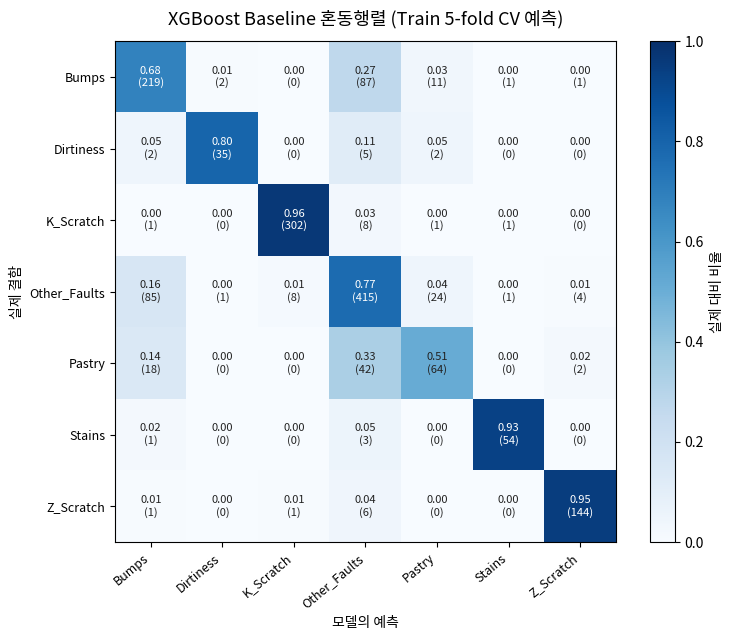

전체 오분류 319건 중 상위 5개 쌍


,,건수,누적 비중
실제,예측,,
Bumps,Other_Faults,87,0.2730
Other_Faults,Bumps,85,0.5390
Pastry,Other_Faults,42,0.6710
Other_Faults,Pastry,24,0.7460
Pastry,Bumps,18,0.8030


In [6]:
fig, ax, cm = plot_confusion_matrix(
    y_train, pred_xgb, labels=list(CLASSES), normalize=True,
    title="XGBoost Baseline 혼동행렬 (Train 5-fold CV 예측)",
    save_name="cv_confusion_matrix_baseline_xgb.png")
plt.show()

# 가장 많이 발생한 오분류 쌍
cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
errors = (cm_df.where(~np.eye(len(CLASSES), dtype=bool)).stack().dropna()
          .sort_values(ascending=False).astype(int))
errors.index.names = ["실제", "예측"]
print(f"전체 오분류 {errors.sum()}건 중 상위 5개 쌍")
top5 = errors.head(5).to_frame("건수")
top5["누적 비중"] = (top5["건수"].cumsum() / errors.sum()).round(3)
top5

**Baseline에서 발견한 문제**
- **소수 유형이 곧 어려운 유형은 아니었습니다.** 가장 적은 Stains(58건)·Dirtiness(44건)는 F1 0.85 이상이고, 가장 낮은 F1은 중간 규모의 **Pastry(0.561)**와 다수 유형인 **Bumps(0.676)**입니다.
- **오분류가 Other_Faults와의 경계에 집중됩니다.** Bumps → Other_Faults 87건, Other_Faults → Bumps 85건, Pastry → Other_Faults 42건, Other_Faults → Pastry 24건이 상위를 차지합니다.
- Pastry의 Recall은 0.508로, 실제 Pastry의 절반가량을 놓칩니다.

**개선 목표 (→ 04 노트북)**
1. Pastry Recall 개선
2. Bumps ↔ Other_Faults 혼동 감소

단순히 "건수가 적은 유형을 늘리는" 불균형 처리보다, **약한 유형과 경계 부근을 보강**하는 방향이 Macro F1 개선에 더 직접적일 것으로 예상합니다.

### 모델이 활용한 Feature: Permutation Importance

**질문:** XGBoost Baseline은 어떤 Feature에 의존해 예측하는가?

Feature 값을 무작위로 섞었을 때 Macro F1이 얼마나 떨어지는지로 중요도를 측정합니다. 학습에 쓰지 않은 **각 Validation fold에서** 계산해 과대평가를 피합니다.

In [7]:
from sklearn.inspection import permutation_importance

imp_list = []
for tr_idx, va_idx in CV.split(X_train, y_enc):
    m = clone(models["XGBoost"]).fit(X_train.iloc[tr_idx], y_enc[tr_idx])
    r = permutation_importance(m, X_train.iloc[va_idx], y_enc[va_idx],
                               scoring="f1_macro", n_repeats=10,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp_list.append(r.importances_mean)

imp = pd.DataFrame(imp_list, columns=X_train.columns)
imp_base = pd.DataFrame({"mean": imp.mean(), "std": imp.std()}).sort_values("mean", ascending=False)
imp_base.head(12).round(4)

,mean,std
Steel_Plate_Thickness,0.1296,0.0426
Length_of_Conveyer,0.0968,0.0307
Pixels_Areas,0.0941,0.0200
TypeOfSteel_A300,0.0731,0.0091
Y_Minimum,0.0570,0.0188
Orientation_Index,0.0492,0.0183
Minimum_of_Luminosity,0.0464,0.0142
Square_Index,0.0448,0.0169
X_Minimum,0.0265,0.0208
Edges_Y_Index,0.0241,0.0172


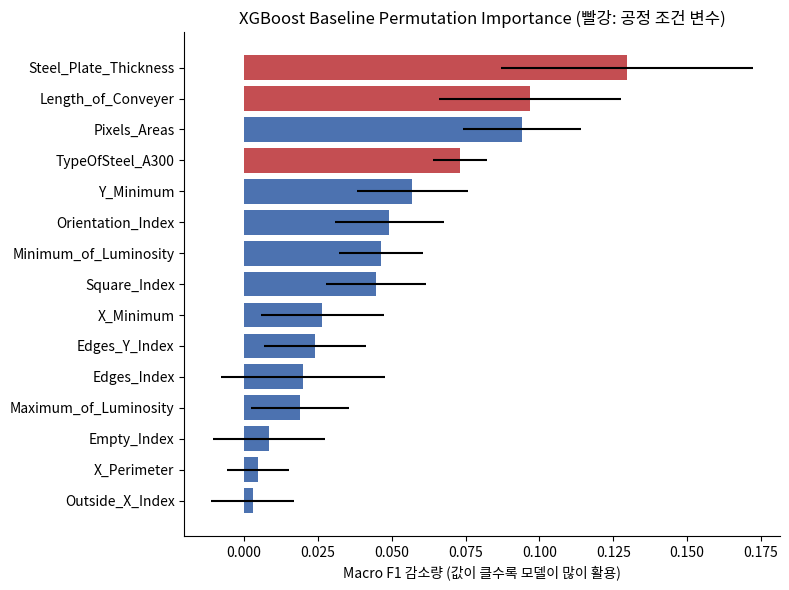

In [8]:
top = imp_base.head(15).iloc[::-1]
process_cols = {"Steel_Plate_Thickness", "Length_of_Conveyer", "TypeOfSteel_A300"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["mean"], xerr=top["std"],
        color=["#C44E52" if c in process_cols else "#4C72B0" for c in top.index])
ax.set_xlabel("Macro F1 감소량 (값이 클수록 모델이 많이 활용)")
ax.set_title("XGBoost Baseline Permutation Importance (빨강: 공정 조건 변수)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance_baseline_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

**확인 결과**
- 상위 1·2·4위가 **공정 조건 변수**(`Steel_Plate_Thickness`, `Length_of_Conveyer`, `TypeOfSteel_A300`)입니다. 결함 형상 변수(`Pixels_Areas`, `Orientation_Index`, `Square_Index`)는 그 다음입니다.
- `Y_Maximum`, `LogOfAreas`의 중요도는 0입니다. 거의 같은 정보를 가진 `Y_Minimum`, `Pixels_Areas`가 남아 있어 하나를 섞어도 다른 변수가 대신하기 때문일 수 있습니다(상관 높은 Feature의 Permutation Importance 과소평가).

**새로 생긴 질문 (가설)**
두께·컨베이어 길이·강종은 결함 "모양"이 아니라 **어떤 강판/생산 조건에서 나왔는지**를 나타냅니다. 같은 강판에서 나온 결함들이 Train fold와 Validation fold에 나뉘어 들어가면, 모델은 "이 공정 조건이면 이 유형"이라는 지름길을 이용할 수 있습니다. → 아래 일반화 점검(README 8.4절)에서 검증합니다.

## 일반화 성능 점검: 공정 조건 그룹 구조 (README 6.1절 발견 2, 8.4절)

**검증할 가설:** (강종, 두께, 컨베이어 길이) 조합이 같은 결함끼리 유형이 몰려 있고, 이 때문에 Stratified CV가 **처음 보는 공정 조건**에 대한 성능을 과대평가한다.

확인 순서
1. 조합별로 유형이 얼마나 한쪽으로 몰려 있는가? (순도)
2. 그 순도는 우연으로도 나올 수 있는 수준인가? (라벨 섞기 비교)
3. Test에도 같은 조합이 있는가?
4. 같은 조합이 Train/Validation에 동시에 들어가지 않게 하면 성능이 얼마나 달라지는가? (Group CV)

In [9]:
KEY = ["TypeOfSteel_A300", "Steel_Plate_Thickness", "Length_of_Conveyer"]
groups = X_train[KEY].astype(str).agg("_".join, axis=1)
group_size = groups.value_counts()

print("Train 조합 수:", groups.nunique())
print(group_size.describe().round(1).to_string())

def weighted_purity(labels):
    """조합 안에서 가장 많은 유형의 비율을 조합 크기로 가중 평균"""
    s = pd.Series(np.asarray(labels)).groupby(groups.values)
    purity = s.agg(lambda x: x.value_counts(normalize=True).iloc[0])
    return (purity * group_size.loc[purity.index]).sum() / group_size.sum()

rng = np.random.default_rng(RANDOM_STATE)
real = weighted_purity(y_train)
perm = [weighted_purity(rng.permutation(y_train.values)) for _ in range(50)]
print(f"\n실제 순도: {real:.3f}")
print(f"라벨을 무작위로 섞었을 때 (50회): 평균 {np.mean(perm):.3f} / 최대 {np.max(perm):.3f}")

# Test는 라벨을 보지 않고 Feature 조합의 존재 여부만 확인
test_keys = set(map(tuple, X_test[KEY].values))
train_keys = set(map(tuple, X_train[KEY].values))
print(f"\nTest 조합 중 Train에도 있는 비율: {len(test_keys & train_keys) / len(test_keys):.3f}")

Train 조합 수: 218
count   218.0000
mean      7.1000
std      12.5000
min       1.0000
25%       1.0000
50%       3.0000
75%       7.0000
max     108.0000



실제 순도: 0.763
라벨을 무작위로 섞었을 때 (50회): 평균 0.431 / 최대 0.446

Test 조합 중 Train에도 있는 비율: 0.844


In [10]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
xgb_group = cv_run(models["XGBoost"], X_train, y_enc, sgkf, groups=groups)

cv_compare = pd.DataFrame([summarize("Stratified CV", xgb_base, y_enc),
                           summarize("Group CV", xgb_group, y_enc)]).set_index("실험")
display(cv_compare.round(3))

pd.DataFrame({
    "Stratified": per_class_f1(xgb_base, y_enc, CLASSES),
    "Group": per_class_f1(xgb_group, y_enc, CLASSES),
}).assign(차이=lambda d: d["Group"] - d["Stratified"]).round(3)

,Accuracy,Macro_P,Macro_R,MacroF1_fold평균,MacroF1_std,MacroF1_CV예측
실험,,,,,,
Stratified CV,0.7940,0.8350,0.8000,0.8110,0.0310,0.8140
Group CV,0.7250,0.7670,0.7180,0.7200,0.0440,0.7540


,Stratified,Group,차이
Bumps,0.6760,0.6350,-0.0410
Dirtiness,0.8540,0.7380,-0.1160
K_Scratch,0.9680,0.9030,-0.0650
Other_Faults,0.7520,0.6700,-0.0820
Pastry,0.5610,0.5430,-0.0180
Stains,0.9390,0.9470,0.0080
Z_Scratch,0.9500,0.8440,-0.1070


**확인 결과**
- Train의 공정 조건 조합은 218개이며, 조합 내 최빈 유형 비율(가중 평균)은 **0.763**입니다. 라벨을 섞으면 평균 0.431, 최대 0.446이므로 우연으로 보기 어렵습니다.
- Test에 등장하는 조합의 **84.4%가 Train에도 있습니다.**
- 같은 조합이 Train/Validation에 함께 들어가지 않게 하면(Group CV) XGBoost Macro F1(fold 평균)이 **0.811 → 0.720**으로 떨어집니다. 유형별로는 Dirtiness(−0.116), Z_Scratch(−0.107), Other_Faults(−0.082)의 하락이 큽니다.
- Group CV는 그룹 크기가 제각각이라 fold마다 크기·유형 구성이 달라집니다. 그래서 CV 예측 기준 값(0.754)과 fold 평균(0.720)의 차이가 Stratified CV보다 크며, 본 프로젝트는 하락폭을 보수적으로 보기 위해 **fold 평균**을 기준으로 보고합니다.

**해석 (가설 포함)**
- 데이터에 강판 ID가 없어 확정할 수는 없지만, 같은 조합의 결함은 같은 강판·생산 조건에서 나왔을 **가능성**이 있습니다.
- Stratified CV 점수는 "이미 본 공정 조건의 다른 결함"에 대한 성능, Group CV 점수는 "처음 보는 공정 조건의 결함"에 대한 성능에 가깝습니다.
- Test 조합 대부분이 Train에 있으므로, Test 점수도 Stratified CV처럼 높게 나올 가능성이 있습니다.

**결정**
- 프로젝트의 공식 모델 선택 기준은 Stratified CV로 유지합니다 (팀 공통 기준).
- 다만 주요 후보는 **Group CV로도 함께 평가**해, 새로운 공정 조건에서의 성능 하락 폭을 한계로 보고합니다 (→ 04).

## Feature Engineering (README 7.5절)

**목적:** Baseline의 핵심 혼동(Bumps·Pastry ↔ Other_Faults)을 줄일 수 있는 정보를 추가합니다.

먼저 두 유형 쌍을 구분할 때 기존 Feature 각각의 구분력(AUC, 0.5 = 구분 못함, 1 = 완벽 구분)을 확인합니다.

In [11]:
def pair_auc(X, a, b, cols=None):
    mask = y_train.isin([a, b])
    yp = (y_train[mask] == a).astype(int)
    cols = cols or list(X.columns)
    s = pd.Series({c: roc_auc_score(yp, X.loc[mask, c]) for c in cols})
    return (s - 0.5).abs() + 0.5            # 방향과 무관한 구분력

pair_df = pd.DataFrame({
    "Bumps_vs_Other": pair_auc(X_train, "Bumps", "Other_Faults"),
    "Pastry_vs_Other": pair_auc(X_train, "Pastry", "Other_Faults"),
})
pair_df.sort_values("Pastry_vs_Other", ascending=False).head(8).round(3)

,Bumps_vs_Other,Pastry_vs_Other
Orientation_Index,0.5320,0.8110
Edges_Y_Index,0.6410,0.7660
Outside_X_Index,0.5790,0.7260
Minimum_of_Luminosity,0.5850,0.7220
Log_X_Index,0.5690,0.7140
Empty_Index,0.6260,0.7070
Square_Index,0.6730,0.7000
Log_Y_Index,0.5740,0.6960


- Bumps vs Other_Faults는 가장 좋은 Feature도 AUC 0.67 수준으로, **단일 Feature로는 거의 구분되지 않습니다.**
- Pastry vs Other_Faults는 방향(`Orientation_Index` 0.81)과 밝기·형상 Feature가 상대적으로 구분력이 있습니다.

이를 바탕으로 밝기 대비, 형태 조밀도, 상대 위치 등 기존 Feature를 조합한 파생 변수를 만들었습니다. 모든 파생 변수는 **한 행 안의 값만으로 계산**하므로 데이터 누수가 없습니다.

| 세트 | 추가 Feature | 의도 |
|---|---|---|
| FE3 | `Luminosity_Range`, `Dark_Depth`, `Compactness` | 밝기 대비, 평균 대비 어두운 정도, 둘레 대비 면적 |
| FE8 | FE3 + `Perimeter_Ratio`, `Log_X/Y_Perimeter`, `Rel_X_Center`, `Lum_Contrast` | 형상 비율, 둘레 왜도 완화, 컨베이어 대비 상대 위치 |
| Position | `x_rel`, `edge_dist_px`, `left_side`, `edge_band10` | 강판 가장자리와의 거리 |

In [12]:
def add_fe3(X):
    X = X.copy()
    mean_lum = X["Sum_of_Luminosity"] / X["Pixels_Areas"]
    X["Luminosity_Range"] = X["Maximum_of_Luminosity"] - X["Minimum_of_Luminosity"]
    X["Dark_Depth"] = mean_lum - X["Minimum_of_Luminosity"]
    X["Compactness"] = (X["X_Perimeter"] + X["Y_Perimeter"]) / np.sqrt(X["Pixels_Areas"])
    return X

def add_fe8(X):
    X = add_fe3(X)
    X["Perimeter_Ratio"] = X["X_Perimeter"] / X["Y_Perimeter"].clip(lower=1)
    X["Log_X_Perimeter"] = np.log10(X["X_Perimeter"].clip(lower=1))
    X["Log_Y_Perimeter"] = np.log10(X["Y_Perimeter"].clip(lower=1))
    X["Rel_X_Center"] = (X["X_Minimum"] + X["X_Maximum"]) / 2 / X["Length_of_Conveyer"]
    lum_sum = (X["Maximum_of_Luminosity"] + X["Minimum_of_Luminosity"]).clip(lower=1)
    X["Lum_Contrast"] = (X["Maximum_of_Luminosity"] - X["Minimum_of_Luminosity"]) / lum_sum
    return X

def add_position(X):
    X = X.copy()
    L = X["Length_of_Conveyer"]
    X["x_rel"] = (X["X_Minimum"] + X["X_Maximum"]) / 2 / L
    X["edge_dist_px"] = np.minimum(X["X_Minimum"], L - X["X_Maximum"])
    X["left_side"] = (X["x_rel"] < 0.5).astype(int)
    X["edge_band10"] = ((X["x_rel"] < 0.1) | (X["x_rel"] > 0.9)).astype(int)
    return X

X_fe3 = add_fe3(X_train)
new3 = ["Luminosity_Range", "Dark_Depth", "Compactness"]
print(pd.DataFrame({
    "Bumps_vs_Other": pair_auc(X_fe3, "Bumps", "Other_Faults", new3),
    "Pastry_vs_Other": pair_auc(X_fe3, "Pastry", "Other_Faults", new3),
}).round(3))

corr = X_fe3.corr().abs()
print("\n기존 Feature와의 최대 상관 (중복 정보 확인)")
for c in new3:
    s = corr[c].drop(new3)
    print(f"  {c:17s} → {s.idxmax()} ({s.max():.3f})")

                  Bumps_vs_Other  Pastry_vs_Other
Luminosity_Range          0.6330           0.7570
Dark_Depth                0.6310           0.7600
Compactness               0.6830           0.5580

기존 Feature와의 최대 상관 (중복 정보 확인)
  Luminosity_Range  → Minimum_of_Luminosity (0.817)
  Dark_Depth        → Minimum_of_Luminosity (0.802)
  Compactness       → Y_Perimeter (0.824)


### Feature 세트별 성능 (Stratified / Group CV)

In [13]:
feature_sets = {"Baseline": X_train, "+FE3": X_fe3, "+FE8": add_fe8(X_train)}
cv_setups = {"Stratified": (CV, None), "Group": (sgkf, groups)}

records, cm_pairs = [], []
for model_name in ["LogReg", "XGBoost"]:
    for cv_name, (splitter, g) in cv_setups.items():
        for set_name, Xs in feature_sets.items():
            res = cv_run(models[model_name], Xs, y_enc, splitter, groups=g)
            f = res["folds"]["f1_macro"]
            records.append({"model": model_name, "cv": cv_name, "features": set_name,
                            "Macro F1": f"{f.mean():.3f} ± {f.std(ddof=0):.3f}"})
            if model_name == "XGBoost":
                cm = pd.crosstab(pd.Series(decode(y_enc), name="실제"),
                                 pd.Series(decode(res["pred"]), name="예측"))
                cm_pairs.append({"cv": cv_name, "features": set_name,
                                 "Pastry→Other": cm.loc["Pastry", "Other_Faults"],
                                 "Bumps↔Other": cm.loc["Bumps", "Other_Faults"] + cm.loc["Other_Faults", "Bumps"]})

display(pd.DataFrame(records).pivot(index=["model", "cv"], columns="features",
                                    values="Macro F1")[list(feature_sets)])
pd.DataFrame(cm_pairs).set_index(["cv", "features"])

features                 Baseline           +FE3           +FE8
model   cv                                                     
LogReg  Group       0.609 ± 0.062  0.605 ± 0.072  0.612 ± 0.074
        Stratified  0.721 ± 0.024  0.723 ± 0.024  0.731 ± 0.030
XGBoost Group       0.720 ± 0.044  0.732 ± 0.032  0.741 ± 0.031
        Stratified  0.811 ± 0.031  0.814 ± 0.020  0.817 ± 0.013

Pastry→Other  Bumps↔Other
cv         features                           
Stratified Baseline            42          172
           +FE3                37          174
           +FE8                36          169
Group      Baseline            45          196
           +FE3                41          196
           +FE8                32          212

### 개선이 우연이 아닌지 확인: 여러 seed에서 fold별 차이

FE 효과는 0.01 안팎으로 fold 간 표준편차보다 작을 수 있습니다. CV seed 3개 × 5 fold = 15번 비교에서 **평균 차이와 FE 쪽이 더 높았던 횟수**를 봅니다. 같은 seed·같은 분할에서 비교하므로 분할 차이에 의한 변동은 제거됩니다.

In [14]:
def paired_diff(model, X_base, X_new, seeds=(0, 1, 2)):
    out = {}
    for cv_name in ["Stratified", "Group"]:
        diffs = []
        for s in seeds:
            if cv_name == "Stratified":
                sp, g = StratifiedKFold(5, shuffle=True, random_state=s), None
            else:
                sp, g = StratifiedGroupKFold(5, shuffle=True, random_state=s), groups
            b = cv_run(model, X_base, y_enc, sp, g)["folds"]["f1_macro"].values
            n = cv_run(model, X_new, y_enc, sp, g)["folds"]["f1_macro"].values
            diffs.extend(n - b)
        d = np.array(diffs)
        out[cv_name] = f"{d.mean():+.3f} (우세 {int((d > 0).sum())}/{len(d)})"
    return out

X_fe8, X_pos = add_fe8(X_train), add_position(X_train)
pd.DataFrame({
    "XGBoost +FE8": paired_diff(models["XGBoost"], X_train, X_fe8),
    "XGBoost +Position": paired_diff(models["XGBoost"], X_train, X_pos),
    "LogReg +Position": paired_diff(models["LogReg"], X_train, X_pos),
}).T

,Stratified,Group
XGBoost +FE8,+0.004 (우세 10/15),+0.017 (우세 11/15)
XGBoost +Position,-0.000 (우세 7/15),+0.000 (우세 8/15)
LogReg +Position,+0.008 (우세 11/15),+0.015 (우세 10/15)


**확인 결과**
- 신규 Feature의 구분력(Pastry vs Other AUC 약 0.76)은 기존 최상위 Feature(`Orientation_Index` 0.81)보다 낮고, 기존 Feature와의 상관도 0.8 이상이어서 **완전히 새로운 정보는 아닙니다.**
- XGBoost + FE8은 Stratified CV에서 개선폭이 작고(평균 +0.004 수준), **Group CV에서 상대적으로 더 일관되게** 좋아졌습니다.
- FE3·FE8은 Pastry → Other_Faults 오분류를 줄였습니다(Stratified 42 → 37/36건, Group 45 → 41/32건). 그러나 Bumps ↔ Other_Faults 혼동은 줄이지 못했고, Group CV의 FE8에서는 오히려 196 → 212건으로 늘었습니다.
- Position 세트는 XGBoost에서 효과가 없었습니다.

**해석 (가설):** 공정 조건 지름길을 쓸 수 없는 Group CV에서는 형상 정보의 가치가 커져 FE 효과가 더 드러난 것으로 보입니다.

**결정:** 이 노트북의 XGBoost 기준에서는 FE8의 개선폭(Stratified CV)이 fold 간 변동보다 작아 **Baseline에는 채택하지 않고**, 새로운 공정 조건에 대한 일반화 개선 후보로 기록합니다. 최종 모델(`07_final_model.ipynb`)은 이와 별도로 파생변수 10개를 추가한 뒤 **처음부터 다시 튜닝**해 36개 Feature를 사용합니다. 파생변수를 그냥 더하기만 하면 효과가 작고, 재튜닝을 함께 해야 효과가 났다는 점은 README 7.5절에 정리했습니다.

## 03 정리 → 04로 넘기는 것

| 항목 | 내용 |
|---|---|
| Baseline 기준 | XGBoost, Macro F1 0.811 ± 0.031 (fold 평균), 0.814 (CV 예측 기준) / Group CV 0.720 ± 0.044 (fold 평균) |
| 개선 목표 | Pastry Recall(0.508), Bumps ↔ Other_Faults 혼동 |
| 후보 모델 | XGBoost, GradientBoosting |
| 일반화 점검 | 주요 후보는 Group CV로도 평가 |
| Feature | XGBoost Baseline은 원본 26개 (FE8은 일반화 개선 후보). 최종 모델은 파생변수 10개 추가 + 재튜닝으로 36개 (06, README 7.5절) |